In [1]:
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import duckdb
import geopandas as gpd

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# carpetas
IN_PATH = Path("../data/external")
IN_PATH.mkdir(exist_ok=True)         # crea la carpeta de entrada si no existe

OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)         # crea la carpeta de salida si no existe

EPSG:4326 



<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

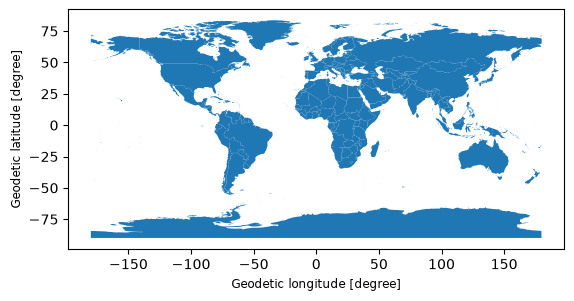

In [2]:
# getting the country boundaries from GISCO

gisco = "https://gisco-services.ec.europa.eu/distribution/v2/countries/geojson/CNTR_RG_20M_2020_4326.geojson"
world = gpd.read_file(gisco)

print(world.crs,"\n")
world.plot()

In [3]:
# getting the data from the web if it doesn't exist locally 

data_path = IN_PATH / f"eu-ets-01-11-2026.csv"

if not data_path.exists():
    url = "https://datahub.io/core/eu-emissions-trading-system/r/eu-ets.csv"
    df = pd.read_csv(url)
    df.to_csv(data_path, index=False)
else:
    df = pd.read_csv(data_path)


print(df.info(),"\n")
print(df.isna().sum(),"\n")
df.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83906 entries, 0 to 83905
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   country_code        83906 non-null  object 
 1   main_activity_code  83906 non-null  object 
 2   main_activity_name  83906 non-null  object 
 3   citl_information    83906 non-null  object 
 4   year                83906 non-null  object 
 5   value               83838 non-null  float64
dtypes: float64(1), object(5)
memory usage: 3.8+ MB
None 

country_code           0
main_activity_code     0
main_activity_name     0
citl_information       0
year                   0
value                 68
dtype: int64 



,country_code,main_activity_code,main_activity_name,citl_information,year,value
0,AT,10,10 Aviation,1. Total allocated allowances (EUA or EUAA),2005,0.0
1,AT,20,20 Combustion of fuels,1. Total allocated allowances (EUA or EUAA),2005,14362552.0
2,AT,20-99,20-99 All stationary installations,1. Total allocated allowances (EUA or EUAA),2005,32412654.0


In [4]:
for code, name in zip(df["main_activity_code"].unique(), df["main_activity_name"].unique()):
    print(f"{code}: {name}")

10: 10 Aviation
20: 20 Combustion of fuels
20-99: 20-99 All stationary installations
21: 21 Refining of mineral oil
21-99: 21-99 All industrial installations (excl. combustion)
22: 22 Production of coke
24: 24 Production of pig iron or steel
29: 29 Production of cement clinker
30: 30 Production of lime, or calcination of dolomite/magnesite
31: 31 Manufacture of glass
32: 32 Manufacture of ceramics
35: 35 Production of pulp
36: 36 Production of paper or cardboard
42: 42 Production of bulk chemicals
99: 99 Other activity opted-in under Art. 24
38: 38 Production of nitric acid
25: 25 Production or processing of ferrous metals
27: 27 Production of secondary aluminium
28: 28 Production or processing of non-ferrous metals
34: 34 Production or processing of gypsum or plasterboard
41: 41 Production of ammonia
43: 43 Production of hydrogen and synthesis gas
26: 26 Production of primary aluminium
33: 33 Manufacture of mineral wool
37: 37 Production of carbon black
50: 50
44: 44 Production of sod

In [5]:
print(df["year"].unique())

['2005' '2006' '2007' '2008' '2009' '2010' '2011' '2012' '2013' '2014'
 '2015' '2016' '2017' '2018' '2019' '2020' '2021' '2022' '2023' '2024'
 '2025' 'Total 1st trading period (05-07)'
 'Total 2nd trading period (08-12)' 'Total 3rd trading period (13-20)'
 'Total 4th trading period (21-30)']


In [6]:
print(df["country_code"].unique())

['AT' 'BE' 'BG' 'CY' 'CZ' 'DE' 'DK' 'EE' 'ES' 'FI' 'FR' 'GB' 'GR' 'HR'
 'HU' 'IE' 'IS' 'IT' 'Innovation fund' 'LI' 'LT' 'LU' 'LV' 'MT'
 'Modernisation Fund' 'NER 300 auctions' 'NL' 'NO' 'PL' 'PT' 'RO' 'RRF'
 'SE' 'SI' 'SK' 'XI']


In [7]:
print(df["citl_information"].unique())

['1. Total allocated allowances (EUA or EUAA)'
 '1.1 Freely allocated allowances'
 '1.1.1 Free allocation to existing entities (Art. 10a(1))'
 '1.1.2 Free allocation from the new entrants reserve (Art. 10a(7))'
 '1.1.4 Swiss Free Allocated allowances for aircraft operators'
 '1.2 Correction to freely allocated allowances (not reflected in EUTL)'
 '1.3 Allowances auctioned or sold (EUAs and EUAAs)'
 '2. Verified emissions' '2.1 EU-ETS Verified Emission'
 '2.1b EU-ETS Verified Emissions (expected, gap-filled for latest year)'
 '2.2 Swiss Verified Emissions for aircraft operators'
 '3. Estimate to reflect current ETS scope for allowances and emissions'
 '4. Total surrendered units'
 '4.1 Surrendered EU allowances (EUAs and EUAAs)'
 '4.2 Surrendered certified emission reductions (CERs)'
 '4.3 Surrendered emission reduction units (ERUs)'
 '4.4 Surrendered Units CHU/CHUAA'
 '2.1c Gap-fill increment (gap-filled minus reported, latest year)'
 '1.1.3 Free allocation for modernisation of electri

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69299 entries, 0 to 69298
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   country_code        69299 non-null  object 
 1   main_activity_code  69299 non-null  object 
 2   main_activity_name  69299 non-null  object 
 3   citl_information    69299 non-null  object 
 4   year                69299 non-null  object 
 5   value               69278 non-null  float64
dtypes: float64(1), object(5)
memory usage: 3.2+ MB
None 

['2005' '2006' '2007' '2008' '2009' '2010' '2011' '2012' '2013' '2014'
 '2015' '2016' '2017' '2018' '2019' '2020' '2021' '2022' '2023' '2024'
 '2025'] 

['AT' 'BE' 'BG' 'CY' 'CZ' 'DE' 'DK' 'EE' 'ES' 'FI' 'FR' 'GB' 'GR' 'HR'
 'HU' 'IE' 'IS' 'IT' 'LI' 'LT' 'LU' 'LV' 'MT' 'NL' 'NO' 'PL' 'PT' 'RO'
 'SE' 'SI' 'SK' 'XI'] 



<Axes: title={'center': 'Total emissions per year (in million tons)'}, xlabel='Year', ylabel='Million tons'>

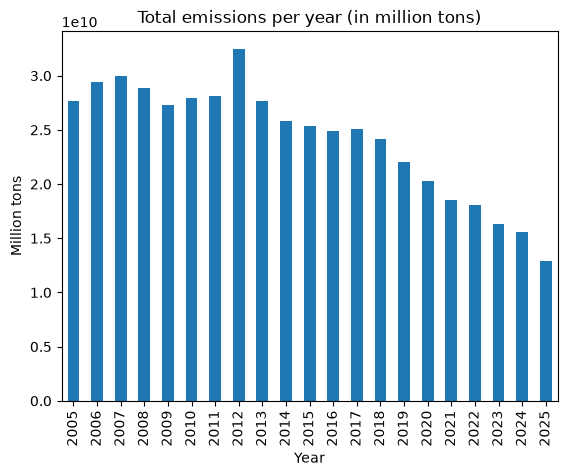

In [8]:
eliminate_year_cols = ['Total 1st trading period (05-07)', 'Total 2nd trading period (08-12)', 'Total 3rd trading period (13-20)', 'Total 4th trading period (21-30)']
eliminate_country_codes = ['Innovation fund', 'Modernisation Fund', 'NER 300 auctions', 'RRF']

years_sql = ", ".join(f"'{v}'" for v in eliminate_year_cols)
codes_sql = ", ".join(f"'{v}'" for v in eliminate_country_codes)

sub_df = duckdb.query(f"""
    SELECT *
    FROM df
    WHERE year NOT IN ({years_sql})
        AND country_code NOT IN ({codes_sql})
""").df()

print(sub_df.info(),"\n")
print(sub_df["year"].unique(), "\n")
print(sub_df["country_code"].unique(), "\n")
sub_df.value.groupby(sub_df.year).sum().plot(kind="bar", title="Total emissions per year (in million tons)", ylabel="Million tons", xlabel="Year")

In [9]:
CAT_VERIFIED = "2. Verified emissions"
CAT_FILLED = "2.1b EU-ETS Verified Emissions (expected, gap-filled for latest year)"

def stationary_emissions(df, year, category=CAT_VERIFIED):
    sel = df[
        (df["citl_information"] == category)
        & (df["year"].astype(str) == year)
        & (df["main_activity_code"].astype(str) == "20-99")
    ]
    return sel.groupby("country_code")["value"].sum()

# Comprobación: DACH-Region 2025 con cada categoría (Mt)
for cat in (CAT_VERIFIED, CAT_FILLED):
    # Deutschland emissions in 2025 (Mt)
    print("DE", cat[:30], round(stationary_emissions(sub_df, '2025', cat).get("DE", float("nan")) / 1e6, 1))
    # Österreich emissions in 2025 (Mt)
    print("AT", cat[:30], round(stationary_emissions(sub_df, '2025', cat).get("AT", float("nan")) / 1e6, 1))
    # In der Schweiz emissions in 2025 (Mt)
    print("CH", cat[:30], round(stationary_emissions(sub_df, '2025', cat).get("CH", float("nan")) / 1e6, 1))

DE 2. Verified emissions 263.6
AT 2. Verified emissions 25.6
CH 2. Verified emissions nan
DE 2.1b EU-ETS Verified Emissions 265.3
AT 2.1b EU-ETS Verified Emissions 25.6
CH 2.1b EU-ETS Verified Emissions nan


### Option A

In [10]:
# setting the base and end years for comparison
BASE_YEAR = "2005"
END_YEAR = "2025"
END_CAT = CAT_FILLED if END_YEAR == "2025" else CAT_VERIFIED   # gap-filled solo para el último año

# calculating the percentage change in emissions from the base year to the end year
base = stationary_emissions(sub_df, BASE_YEAR)
end = stationary_emissions(sub_df, END_YEAR, END_CAT)

# creating a DataFrame to hold the base and end emissions, dropping any rows with NaN values
change = pd.DataFrame({"base": base, "end": end}).dropna()
change = change[change["base"] > 0]
change["pct"] = (change["end"] / change["base"] - 1) * 100
change = change.reset_index()
change["country_code"] = change["country_code"].replace({"GR": "EL"})
print(change.sort_values("pct")[["country_code", "pct"]].round(1).to_string(index=False))

# merging world data 
europe_chg = world.merge(change, left_on="CNTR_ID", right_on="country_code", how="left").to_crs(3035) # EPSG:3035 is a projected coordinate system suitable for Europe

country_code   pct
          DK -70.2
          PT -68.7
          EE -67.3
          FI -64.1
          EL -63.7
          MT -63.5
          XI -63.3
          LU -62.6
          SI -57.9
          ES -57.3
          HU -57.1
          IT -55.1
          FR -53.4
          IE -52.5
          CZ -51.4
          DE -44.1
          SK -42.0
          LV -41.8
          BE -34.8
          LT -30.2
          PL -28.2
          AT -23.3
          NL -23.0
          SE -16.5
          CY -14.7


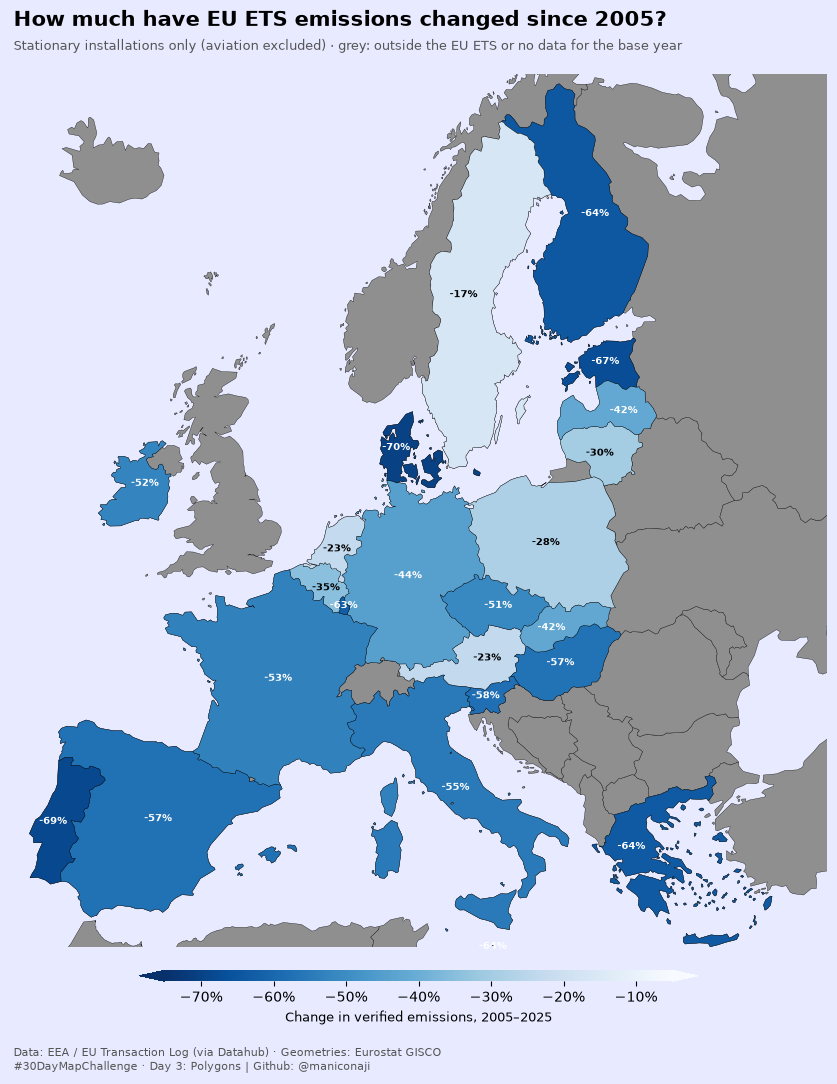

In [11]:
# ---- Map ----
fig, ax = plt.subplots(figsize=(12, 12), facecolor="#E8EBFF")

norm = Normalize(vmin=-75, vmax=-5)   # ajusta según los datos que veas
cmap = "Blues_r"                                      # azul = reducción, rojo = aumento

# Background: countries without data
europe_chg.plot(ax=ax, color="#8F8F8F", edgecolor="k", linewidth=0.25)
data = europe_chg.dropna(subset=["pct"])
data.plot(
    column="pct", 
    ax=ax, 
    cmap=cmap, 
    norm=norm,
    edgecolor="k", 
    linewidth=0.25)

# Labels for the 12 largest emitters in the end year
top = data.copy() # data.nlargest(12, "end")
top["pt"] = top.geometry.representative_point()
for _, r in top.iterrows():
    if r['pct'] < -40:
        ax.annotate(
            f"{r['pct']:+.0f}%", xy=(r["pt"].x, r["pt"].y),
            ha="center", va="center", fontsize=7,
            fontweight="bold", color="#FFFFFF")
    else:
        ax.annotate(
            f"{r['pct']:+.0f}%", xy=(r["pt"].x, r["pt"].y),
            ha="center", va="center", fontsize=7,
            fontweight="bold", color="#000000")

sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(
    sm, ax=ax, orientation="horizontal",
    fraction=0.03, pad=0.025, shrink=0.60, aspect=50, extend="both")
ticks = [-70, -60, -50, -40, -30, -20, -10]
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t}%".replace("-", "−") for t in ticks])
cbar.set_label(f"Change in verified emissions, {BASE_YEAR}–{END_YEAR}", fontsize=9)
cbar.outline.set_visible(False)

ax.set_xlim(2.55e6, 6.2e6)
ax.set_ylim(1.45e6, 5.35e6)
ax.set_axis_off()

fig.text(
    0.175, 0.92,
    f"How much have EU ETS emissions changed since {BASE_YEAR}?", 
    ha="left", fontsize=15, fontweight="bold")
fig.text(
    0.175, 0.90,
    "Stationary installations only (aviation excluded) · grey: outside the EU ETS or no data for the base year",
    ha="left", fontsize=9.5, color="#555")
fig.text(
    0.175, 0.05,
    "Data: EEA / EU Transaction Log (via Datahub) · Geometries: Eurostat GISCO\n"
    "#30DayMapChallenge · Day 3: Polygons | Github: @maniconaji",
    fontsize=8, color="#555")

# plt.savefig(OUT / "day03_polygons_change.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

### Option 2

In [12]:
BASE, END = int(BASE_YEAR), int(END_YEAR)

# ------------------------------------------------------------------
# 1) Time series: stationary installations, verified (gap-filled for 2025)
# ------------------------------------------------------------------
d = sub_df[sub_df["main_activity_code"].astype(str) == "20-99"].copy()
d["year"] = pd.to_numeric(d["year"], errors="coerce")
d = d.dropna(subset=["year"])
d["year"] = d["year"].astype(int)

verified = d[(d["citl_information"] == CAT_VERIFIED) & (d["year"] < END)]
filled = d[(d["citl_information"] == CAT_FILLED) & (d["year"] == END)]
series = pd.concat([verified, filled])

pivot = series.pivot_table(index="year", columns="country_code", values="value", aggfunc="sum")
pivot.columns = [("EL" if c == "GR" else c) for c in pivot.columns]

# Keep real countries only (those with a polygon) and with base-year data
pivot = pivot[[c for c in pivot.columns if c in set(world["CNTR_ID"])]]
pivot = pivot.loc[:, pivot.loc[BASE] > 0]

index = pivot.div(pivot.loc[BASE]) * 100
eu_total = pivot.sum(axis=1)
eu_index = eu_total / eu_total.loc[BASE] * 100

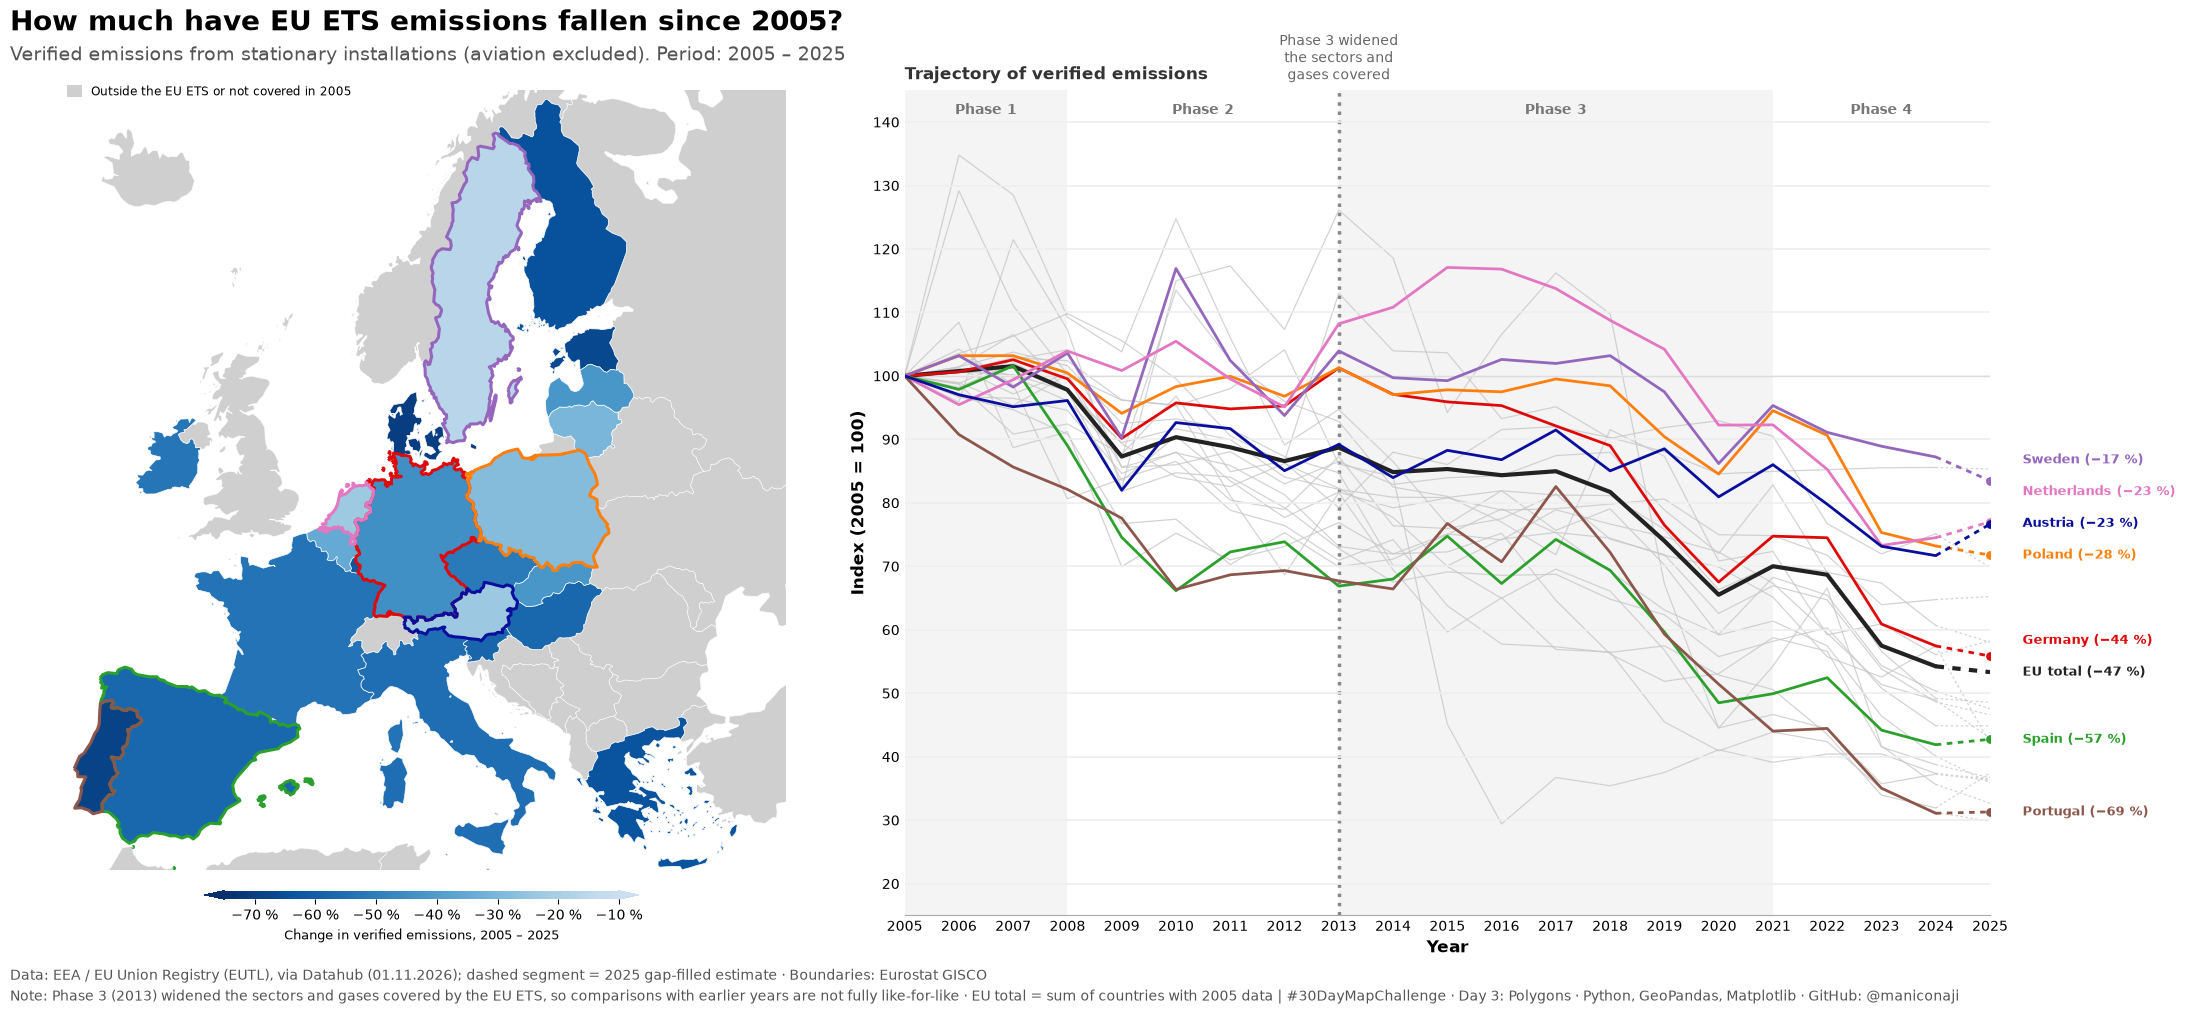

In [13]:
# ------------------------------------------------------------------
# 2) Highlighted countries
# ------------------------------------------------------------------
highlight = {
    "DE": ("Germany",    "#de0909"),
    "PL": ("Poland",     "#ff7f0e"),
    "ES": ("Spain",      "#2ca02c"),
    "SE": ("Sweden",     "#9467bd"),
    "NL": ("Netherlands","#e377c2"),
    "PT": ("Portugal",   "#8c564b"),
    "AT": ("Austria",    "#090e9d"),
}

# blank space
NBSP = "\u00a0"

# ------------------------------------------------------------------
# 3) Figure
# ------------------------------------------------------------------
plt.style.use("default")

H  = 10
W  = 2.25 * H
fig = plt.figure(figsize=(W, H), facecolor="white")
gs = GridSpec(1, 2, width_ratios=[1, 1.25], figure=fig)
ax_map = fig.add_subplot(gs[0])
ax_ts = fig.add_subplot(gs[1])

# ---------------- Map ----------------
# cmap
norm = Normalize(vmin=-75, vmax=-10)
base_cmap = mpl.colormaps["Blues_r"]
cmap = LinearSegmentedColormap.from_list("blues_trunc", base_cmap(np.linspace(0, 0.78, 256)))

# plotting the background and the countries with changes
europe_chg.plot(ax=ax_map, color="#cfcfcf", edgecolor="white", linewidth=0.4)
data = europe_chg.dropna(subset=["pct"])
data.plot(column="pct", ax=ax_map, cmap=cmap, norm=norm, edgecolor="white", linewidth=0.5)

# Outline highlighted countries with their line colour
for code, (_, color) in highlight.items():
    sub = europe_chg[europe_chg["CNTR_ID"] == code]
    if not sub.empty:
        sub.boundary.plot(ax=ax_map, color=color, linewidth=2.2)

# Labels on the largest polygon of each country
# parts = data.explode(index_parts=False).reset_index(drop=True)
# parts["area"] = parts.geometry.area
# largest = parts.sort_values("area").groupby("country_code").tail(1).copy()
# largest["pt"] = largest.geometry.representative_point()
# for _, r in largest.iterrows():
#     txt_color = "white" if r["pct"] < -45 else "#222"
#     ax_map.annotate(f"{r['pct']:.0f}%", xy=(r["pt"].x, r["pt"].y),
#                     ha="center", va="center", fontsize=8.5,
#                     fontweight="bold", color=txt_color)

ax_map.set_xlim(2.55e6, 6.2e6)
ax_map.set_ylim(1.45e6, 5.35e6)
ax_map.set_axis_off()

ax_map.legend(
    handles=[Patch(facecolor="#cfcfcf", edgecolor="none", label="Outside the EU ETS or not covered in 2005")],
    loc="upper left", bbox_to_anchor=(0.00, 1.02),
    frameon=False, fontsize=8.5, handlelength=1.2, handleheight=1.2,
)

sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(
    sm, ax=ax_map, orientation="horizontal",
    fraction=0.03, pad=0.025, shrink=0.5, aspect=50, extend="both")
ticks = [-70, -60, -50, -40, -30, -20, -10]
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t}{NBSP}%".replace("-", "−") for t in ticks])
cbar.set_label(f"Change in verified emissions, {BASE} – {END}", fontsize=9)
cbar.outline.set_visible(False)

# ---------------- Time series ----------------
years = index.index.values
solid = years <= END - 1       # verified data
# last segment (END-1 -> END) is dashed because END is a gap-filled estimate

def plot_series(y, color, lw, alpha=1.0, zorder=2):
    ax_ts.plot(
        years[solid], y.values[solid], color=color, lw=lw,
        alpha=alpha, zorder=zorder, solid_capstyle="round")
    ax_ts.plot(
        years[-2:], y.values[-2:], color=color, lw=lw, alpha=alpha,
        zorder=zorder, linestyle=(0, (2, 2)))

# Background: all other countries
for c in index.columns:
    if c not in highlight:
        plot_series(index[c], "#c8c8c8", 0.9, alpha=0.8, zorder=1)

# EU total
plot_series(eu_index, "#222222", 3.0, zorder=3)

# Highlighted countries
for code, (name, color) in highlight.items():
    if code in index.columns:
        plot_series(index[code], color, 2.0, zorder=4)
        ax_ts.scatter([END], [index[code].iloc[-1]], color=color, s=28, zorder=5)

# End labels with a simple anti-overlap nudge
labels = [(index[c].iloc[-1], highlight[c][0], highlight[c][1]) for c in highlight if c in index.columns]
labels.append((eu_index.iloc[-1], "EU total", "#222222"))
labels.sort(key=lambda t: t[0])
MIN_GAP = 5.0
ys = [l[0] for l in labels]
for i in range(1, len(ys)):
    if ys[i] - ys[i - 1] < MIN_GAP:
        ys[i] = ys[i - 1] + MIN_GAP
for (val, name, color), y_txt in zip(labels, ys):
    ax_ts.annotate(
        f"{name} ({val - 100:+.0f}{NBSP}%)".replace("-", "−"),
        xy=(END, val), xytext=(END + 0.6, y_txt),
        fontsize=9, color=color, fontweight="bold", va="center",
        annotation_clip=False)

# ---- ETS phases as light bands ----
# eliminate_year_cols = ['Total 1st trading period (05-07)', 'Total 2nd trading period (08-12)', 'Total 3rd trading period (13-20)', 'Total 4th trading period (21-30)']
phases = [
    (2005, 2008, "Phase 1", "#f4f4f4"), # 2005 -> 2007 + 1
    (2008, 2013, "Phase 2", "#ffffff"), # 2008 -> 2012 + 1
    (2013, 2021, "Phase 3", "#f4f4f4"), # 2013 -> 2020 + 1
    (2021, 2025, "Phase 4", "#ffffff"), # 2005 -> 2025
]
for x0, x1, label, shade in phases:
    ax_ts.axvspan(x0, x1, color=shade, zorder=0, lw=0)
    ax_ts.text(
        (max(x0, BASE) + x1) / 2, 143, label, ha="center", va="top",
        fontsize=10, color="#777", fontweight="bold")

# 2013 scope change marker
ax_ts.axvline(2013, color="#888", lw=2.5, ls=":", zorder=0)
ax_ts.text(
    2013, 146, "Phase 3 widened\nthe sectors and\ngases covered", 
    fontsize=10, color="#666", va="bottom", ha="center")

ax_ts.axhline(100, color="#888", lw=0.8, zorder=0)
ax_ts.set_xticks(range(BASE, END + 1, 1))
ax_ts.set_yticks(range(10, 151, 10))
ax_ts.set_xlim(BASE, END)
ax_ts.set_ylim(15,145)
ax_ts.set_ylabel(f"Index ({BASE} = 100)", fontsize=12, fontweight="bold")
ax_ts.set_xlabel("Year", fontsize=12, fontweight="bold")
ax_ts.tick_params(labelsize=10, length=0)
ax_ts.grid(axis="y", color="#eee", lw=1.2)
for s in ("top", "right", "left"):
    ax_ts.spines[s].set_visible(False)
ax_ts.spines["bottom"].set_color("#aaa")
ax_ts.set_title(
    "Trajectory of verified emissions", fontsize=12, fontweight="bold", loc="left", color="#333", pad=8)

# ---------------- Titles and footer ----------------
fig.text(
    0.02, 0.96, 
    f"How much have EU ETS emissions fallen since {BASE}?",
    fontsize=20, fontweight="bold", ha="left")
fig.text(
    0.02, 0.93,
    f"Verified emissions from stationary installations (aviation excluded). Period: {BASE} – {END}",
    fontsize=14, color="#555", ha="left")
fig.text(
    0.02, 0.025,
    f"Data: EEA / EU Union Registry (EUTL), via Datahub (01.11.2026); dashed segment = {END} gap-filled estimate · Boundaries: Eurostat GISCO\n"
    "Note: Phase 3 (2013) widened the sectors and gases covered by the EU ETS, so comparisons with earlier years are not fully like-for-like · "
    "EU total = sum of countries with 2005 data | "
    "#30DayMapChallenge · Day 3: Polygons · Python, GeoPandas, Matplotlib · GitHub: @maniconaji",
    fontsize=10, color="#555", ha="left", va="top", linespacing=1.5)

# Leave room on the right for the end labels
fig.subplots_adjust(left=0.01, right=0.9, top=0.90, bottom=0.075, wspace=0.05)

plt.savefig(OUT / "day03_polygons_map_timeseries.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()